# ✅ Missing Value Handling: Mean vs Median Imputation (Titanic)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer


In [2]:
# ==========================================================
# 1) Load Dataset
# ==========================================================

df = pd.read_csv('titanic_toy.csv')

print("✅ Dataset Shape:", df.shape)
print(df.head(), "\n")

print("✅ Dataset Info:")
print(df.info(), "\n")

print("✅ Missing Ratio:")
print(df.isnull().mean(), "\n")

✅ Dataset Shape: (891, 4)
    Age     Fare  Family  Survived
0  22.0   7.2500       1         0
1  38.0  71.2833       1         1
2  26.0   7.9250       0         1
3  35.0  53.1000       1         1
4  35.0   8.0500       0         0 

✅ Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Age       714 non-null    float64
 1   Fare      846 non-null    float64
 2   Family    891 non-null    int64  
 3   Survived  891 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 28.0 KB
None 

✅ Missing Ratio:
Age         0.198653
Fare        0.050505
Family      0.000000
Survived    0.000000
dtype: float64 



In [3]:
# ==========================================================
# 2) Split into X and y
# ==========================================================

X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=2
)

print("✅ Train shape:", X_train.shape)
print("✅ Test shape:", X_test.shape)

print("\n✅ Train Missing Ratio:")
print(X_train.isnull().mean(), "\n")

✅ Train shape: (712, 3)
✅ Test shape: (179, 3)

✅ Train Missing Ratio:
Age       0.207865
Fare      0.050562
Family    0.000000
dtype: float64 



In [4]:

# ==========================================================
# 3) Manual Imputation (Pandas) - Mean vs Median
# ==========================================================
# ✅ Important improvement:
# Always create a copy to avoid SettingWithCopyWarning

X_train_copy = X_train.copy()

# Calculating statistics ONLY from TRAIN (NO leakage)
mean_age = X_train_copy['Age'].mean()
median_age = X_train_copy['Age'].median()

mean_fare = X_train_copy['Fare'].mean()
median_fare = X_train_copy['Fare'].median()

print("✅ Mean Age:", mean_age)
print("✅ Median Age:", median_age)
print("✅ Mean Fare:", mean_fare)
print("✅ Median Fare:", median_fare)

# Create new imputed columns
X_train_copy.loc[:, 'Age_median'] = X_train_copy['Age'].fillna(median_age)
X_train_copy.loc[:, 'Age_mean'] = X_train_copy['Age'].fillna(mean_age)

X_train_copy.loc[:, 'Fare_median'] = X_train_copy['Fare'].fillna(median_fare)
X_train_copy.loc[:, 'Fare_mean'] = X_train_copy['Fare'].fillna(mean_fare)

print("\n✅ Sample after adding imputed columns:")
print(X_train_copy.sample(5), "\n")


✅ Mean Age: 29.78590425531915
✅ Median Age: 28.75
✅ Mean Fare: 32.61759689349112
✅ Median Fare: 14.4583

✅ Sample after adding imputed columns:
      Age     Fare  Family  Age_median   Age_mean  Fare_median  Fare_mean
535   7.0  26.2500       2        7.00   7.000000      26.2500  26.250000
2    26.0   7.9250       0       26.00  26.000000       7.9250   7.925000
256   NaN  79.2000       0       28.75  29.785904      79.2000  79.200000
189  36.0   7.8958       0       36.00  36.000000       7.8958   7.895800
860  41.0      NaN       2       41.00  41.000000      14.4583  32.617597 



In [5]:
# ==========================================================
# 4) Compare Variance Before vs After Imputation
# ==========================================================

print("✅ Variance Comparison:\n")

print("Original Age variance:", X_train_copy['Age'].var())
print("Age variance after MEDIAN:", X_train_copy['Age_median'].var())
print("Age variance after MEAN:", X_train_copy['Age_mean'].var(), "\n")

print("Original Fare variance:", X_train_copy['Fare'].var())
print("Fare variance after MEDIAN:", X_train_copy['Fare_median'].var())
print("Fare variance after MEAN:", X_train_copy['Fare_mean'].var(), "\n")



✅ Variance Comparison:

Original Age variance: 204.3495133904614
Age variance after MEDIAN: 161.9895663346054
Age variance after MEAN: 161.81262452718673 

Original Fare variance: 2448.197913706318
Fare variance after MEDIAN: 2340.0910219753637
Fare variance after MEAN: 2324.2385256705547 



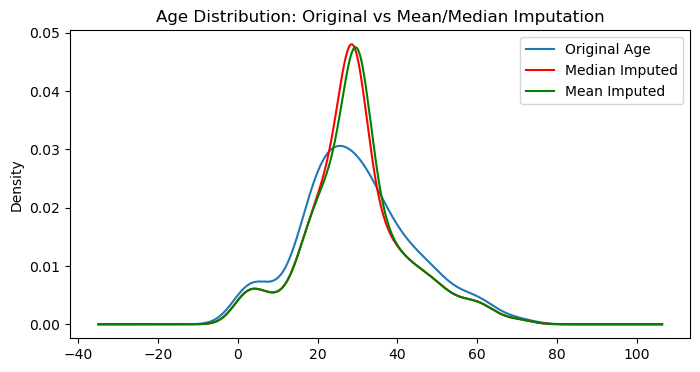

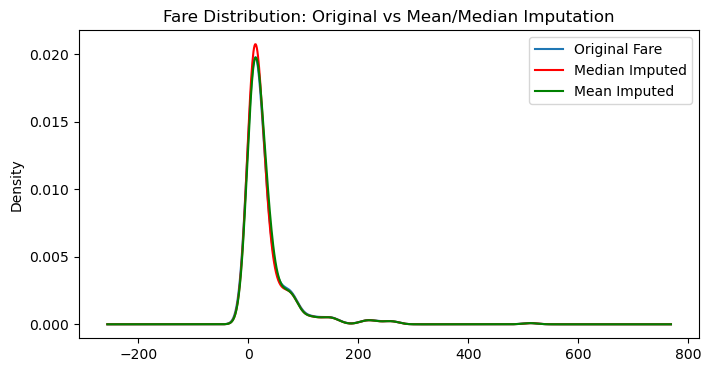

In [6]:
# ==========================================================
# 5) Distribution Comparison (KDE Plot)
# ==========================================================

# ---- Age KDE ----
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(111)

X_train_copy['Age'].plot(kind='kde', ax=ax, label="Original Age")
X_train_copy['Age_median'].plot(kind='kde', ax=ax, color='red', label="Median Imputed")
X_train_copy['Age_mean'].plot(kind='kde', ax=ax, color='green', label="Mean Imputed")

ax.set_title("Age Distribution: Original vs Mean/Median Imputation")
ax.legend()
plt.show()


# ---- Fare KDE ----
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(111)

X_train_copy['Fare'].plot(kind='kde', ax=ax, label="Original Fare")
X_train_copy['Fare_median'].plot(kind='kde', ax=ax, color='red', label="Median Imputed")
X_train_copy['Fare_mean'].plot(kind='kde', ax=ax, color='green', label="Mean Imputed")

ax.set_title("Fare Distribution: Original vs Mean/Median Imputation")
ax.legend()
plt.show()

In [7]:
# ==========================================================
# 6) Correlation & Covariance (Optional Analysis)
# ==========================================================

print("✅ Covariance Matrix:")
print(X_train_copy.cov(), "\n")

print("✅ Correlation Matrix:")
print(X_train_copy.corr(), "\n")

✅ Covariance Matrix:
                    Age         Fare     Family  Age_median    Age_mean  \
Age          204.349513    70.719262  -6.498901  204.349513  204.349513   
Fare          70.719262  2448.197914  17.258917   57.957599   55.603719   
Family        -6.498901    17.258917   2.735252   -5.112563   -5.146106   
Age_median   204.349513    57.957599  -5.112563  161.989566  161.812625   
Age_mean     204.349513    55.603719  -5.146106  161.812625  161.812625   
Fare_median   64.858859  2448.197914  16.476305   53.553455   51.358000   
Fare_mean     66.665205  2448.197914  16.385048   55.023037   52.788341   

             Fare_median    Fare_mean  
Age            64.858859    66.665205  
Fare         2448.197914  2448.197914  
Family         16.476305    16.385048  
Age_median     53.553455    55.023037  
Age_mean       51.358000    52.788341  
Fare_median  2340.091022  2324.238526  
Fare_mean    2324.238526  2324.238526   

✅ Correlation Matrix:
                  Age      Fare   

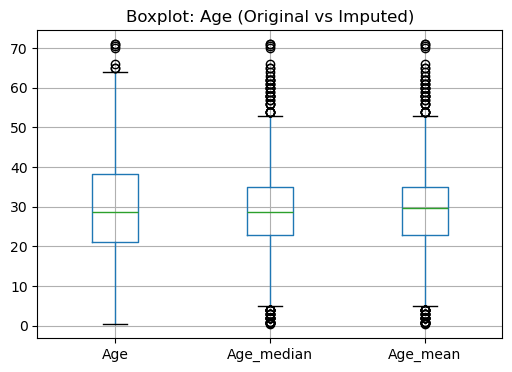

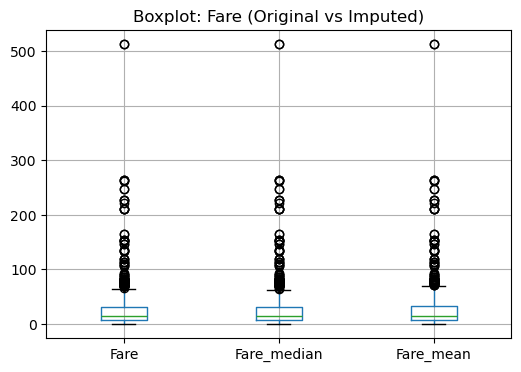

In [8]:
# ==========================================================
# 7) Boxplots (Compare Spread & Outliers)
# ==========================================================

plt.figure(figsize=(6,4))
X_train_copy[['Age', 'Age_median', 'Age_mean']].boxplot()
plt.title("Boxplot: Age (Original vs Imputed)")
plt.show()

plt.figure(figsize=(6,4))
X_train_copy[['Fare', 'Fare_median', 'Fare_mean']].boxplot()
plt.title("Boxplot: Fare (Original vs Imputed)")
plt.show()


In [9]:

# ==========================================================
# ✅ 8) Using Sklearn (Best Practice)
# ==========================================================

# Again split (fresh)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=2
)

# Imputers
imputer_age = SimpleImputer(strategy='median')
imputer_fare = SimpleImputer(strategy='mean')   # default is mean anyway

# ColumnTransformer
trf = ColumnTransformer(
    transformers=[
        ('imputer_age', imputer_age, ['Age']),
        ('imputer_fare', imputer_fare, ['Fare'])
    ],
    remainder='passthrough'
)

# Fit only on train
trf.fit(X_train)

print("✅ Age median used:", trf.named_transformers_['imputer_age'].statistics_)
print("✅ Fare mean used:", trf.named_transformers_['imputer_fare'].statistics_)

# Transform both train and test
X_train_trf = trf.transform(X_train)
X_test_trf = trf.transform(X_test)

print("\n✅ Transformed Train Data (first 5 rows):")
print(X_train_trf[:5])

✅ Age median used: [28.75]
✅ Fare mean used: [32.61759689]

✅ Transformed Train Data (first 5 rows):
[[40.     27.7208  0.    ]
 [ 4.     16.7     2.    ]
 [47.      9.      0.    ]
 [ 9.     31.3875  6.    ]
 [20.      9.8458  0.    ]]
